# Tarea 1 – Parte 1: Recolección y limpieza de noticias

**Pregunta guía:** ¿se pueden convertir titulares de un diario peruano en un clasificador de noticias?

| Configuración | Valor |
| :--- | :--- |
| Fecha de descarga | **2026-10-18** (hora de Lima) |
| Opción elegida | **B – El Comercio** (350–400 noticias, ~90–100 por categoría) |
| URL base | `https://elcomercio.pe` |
| `robots.txt` | `https://elcomercio.pe/robots.txt` |
| Índices de sitemaps (declarados en `robots.txt`) | `https://elcomercio.pe/sitemap/{seccion}/?outputType=xml` |
| Sitemaps usados (URL y fecha de cada nota) | `https://elcomercio.pe/sitemap/web/{seccion}/?outputType=xml` con `seccion` = `politica`, `economia`, `deporte-total`, `tecnologia` |
| Titular, bajada y fecha | HTML de cada nota (`requests` + `BeautifulSoup`) |
| Categorías finales | `politica`, `economia`, `deportes`, `ciencia_tecnologia` |

**¿Por qué sitemaps + HTML y no solo RSS?**

- El Comercio tiene un RSS oficial por sección (`/arc/outboundfeeds/google-news-feed/category/{seccion}/`), pero solo cubre las últimas ~48 horas. El 18/10 traía 20 notas de política, 13 de economía, 86 de deportes y 15 de tecnología, así que no alcanza para ~90 por categoría.
- Los sitemaps de sección que publica `robots.txt` listan las 100 notas más recientes de cada sección, con su URL y su fecha. Con esa lista se visita cada nota **una sola vez** para leer el titular, la bajada y la fecha de publicación.
- Se descartó La República (opciones A y C) porque sus RSS y sitemaps por sección traen solo entre 6 y 21 notas, y su `robots.txt` prohíbe paginar las secciones (`Disallow: /*/pag/`).

**Buenas prácticas de scraping:** se revisa `robots.txt` antes de descargar, se usa un `User-Agent` descriptivo con enlace de contacto, hay una pausa de 1.5 s entre solicitudes y como máximo 1 reintento por URL. Todo lo descargado se respalda en `datos/raw/`; al reejecutar el notebook no se vuelve a pedir al servidor lo que ya está guardado.

In [1]:
import json
import time
import urllib.robotparser
from datetime import date
from pathlib import Path
from urllib.parse import urlparse

import pandas as pd
import plotly.express as px
import plotly.io as pio
import requests
import truststore
from bs4 import BeautifulSoup

# Valida HTTPS con los certificados del sistema operativo. En Windows, el antivirus
# intercepta HTTPS con su propio certificado raíz, que el certifi de requests no conoce.
truststore.inject_into_ssl()

# Plotly: interactivo en Jupyter/VS Code + copia PNG para que GitHub muestre los gráficos
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width = 950
pio.templates.default = "plotly_white"
pd.set_option("display.max_colwidth", 110)

OPCION = "B"
MEDIO = "El Comercio"
BASE = "https://elcomercio.pe"
USER_AGENT = ("Mozilla/5.0 (compatible; TareaDiplomadoPython/1.0; uso academico; "
              "+https://github.com/IvettexMamani/diplomado-python-2026)")
PAUSA_SEG = 1.5      # entre 1 y 2 s entre solicitudes
MAX_REINTENTOS = 1   # como máximo 1 reintento por URL

# Secciones del diario cuyo sitemap se recorre
SITEMAPS = ["politica", "economia", "deporte-total", "tecnologia"]
ETIQUETAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]

DATOS = Path("datos")
RAW = DATOS / "raw"
(RAW / "sitemaps").mkdir(parents=True, exist_ok=True)

print("Fecha de ejecución:", date.today().isoformat())
print(f"Opción {OPCION}: {MEDIO} ({BASE})")

Fecha de ejecución: 2026-10-18
Opción B: El Comercio (https://elcomercio.pe)


## 1. Revisión de `robots.txt`
Se descarga `robots.txt` (y se guarda una copia en `datos/raw/`), se leen las reglas que aplican a cualquier robot (`User-agent: *`) y se comprueba con `urllib.robotparser` que el `User-Agent` del proyecto puede leer los sitemaps y las notas.

In [2]:
sesion = requests.Session()
sesion.headers.update({"User-Agent": USER_AGENT, "Accept-Language": "es-PE,es;q=0.9"})
_ultima = [0.0]  # momento de la última solicitud


def descargar(url):
    # GET respetuoso: pausa mínima entre solicitudes y como máximo 1 reintento.
    r = None
    for intento in range(1 + MAX_REINTENTOS):
        espera = PAUSA_SEG - (time.time() - _ultima[0])
        if espera > 0:
            time.sleep(espera)
        try:
            r = sesion.get(url, timeout=25)
        except requests.RequestException as e:
            print(f"  error de red ({type(e).__name__}) en {url}")
            r = None
        _ultima[0] = time.time()
        if r is not None and r.status_code in (200, 404, 410):
            return r  # éxito, o la página no existe: no tiene sentido reintentar
    return r


archivo_robots = RAW / "robots_elcomercio.txt"
if archivo_robots.exists():
    texto_robots = archivo_robots.read_text(encoding="utf-8")
    print("robots.txt leído del respaldo en datos/raw/")
else:
    r = descargar(f"{BASE}/robots.txt")
    r.raise_for_status()
    texto_robots = r.text
    archivo_robots.write_text(texto_robots, encoding="utf-8")
    print("robots.txt descargado y guardado en datos/raw/")

rp = urllib.robotparser.RobotFileParser()
rp.parse(texto_robots.splitlines())

# Reglas del grupo "User-agent: *", que es el que aplica a nuestro User-Agent
reglas, en_grupo = [], False
for linea in texto_robots.splitlines():
    linea = linea.strip()
    if linea.lower().startswith("user-agent:"):
        en_grupo = linea.split(":", 1)[1].strip() == "*"
    elif en_grupo and linea.lower().startswith(("disallow:", "allow:")):
        reglas.append(linea)
sitemaps_declarados = [linea.split(":", 1)[1].strip() for linea in texto_robots.splitlines()
                       if linea.lower().startswith("sitemap:")]

print("Reglas para 'User-agent: *':", reglas)
print("Sitemaps declarados en robots.txt:", len(sitemaps_declarados))
print("Índices de las 4 secciones declarados:",
      all(f"{BASE}/sitemap/{s}/?outputType=xml" in sitemaps_declarados for s in SITEMAPS))

robots.txt leído del respaldo en datos/raw/
Reglas para 'User-agent: *': ['Disallow: /catalogo/', 'Disallow: /buscar/', 'Disallow: /archivo/todas/19*', 'Disallow: /archivo/todas/200*']
Sitemaps declarados en robots.txt: 44
Índices de las 4 secciones declarados: True


In [3]:
pruebas = {
    "Índice de sitemaps de política": f"{BASE}/sitemap/politica/?outputType=xml",
    "Sitemap web de deportes": f"{BASE}/sitemap/web/deporte-total/?outputType=xml",
    "Nota de economía (ejemplo)": f"{BASE}/economia/mercados/ejemplo-noticia/",
    "Nota de tecnología (ejemplo)": f"{BASE}/tecnologia/actualidad/ejemplo-noticia/",
    "Buscador": f"{BASE}/buscar/ejemplo/",
    "Catálogo": f"{BASE}/catalogo/",
}
pd.DataFrame({"recurso": list(pruebas), "url": list(pruebas.values()),
              "permitido": [rp.can_fetch(USER_AGENT, u) for u in pruebas.values()]})

,recurso,url,permitido
0,Índice de sitemaps de política,https://elcomercio.pe/sitemap/politica/?outputType=xml,True
1,Sitemap web de deportes,https://elcomercio.pe/sitemap/web/deporte-total/?outputType=xml,True
2,Nota de economía (ejemplo),https://elcomercio.pe/economia/mercados/ejemplo-noticia/,True
3,Nota de tecnología (ejemplo),https://elcomercio.pe/tecnologia/actualidad/ejemplo-noticia/,True
4,Buscador,https://elcomercio.pe/buscar/ejemplo/,False
5,Catálogo,https://elcomercio.pe/catalogo/,False


**Conclusión:** para cualquier robot, `robots.txt` solo prohíbe `/catalogo/`, `/buscar/` y el archivo histórico (`/archivo/todas/19*`, `/archivo/todas/200*`). El bloqueo total (`Disallow: /`) aplica solo a una lista de descargadores masivos (HTTrack, wget, WebZIP, etc.), y nuestro `User-Agent` no está en ella. Los sitemaps de sección y las páginas de las notas están permitidos.

**Fuente definida:** sitemaps oficiales por sección + HTML de cada nota.

## 2. Extracción

### 2.1 Sitemaps por sección
Para cada sección se abre su índice declarado en `robots.txt` y se toma el sitemap `web`, que lista las 100 notas más recientes. El XML crudo se guarda en `datos/raw/sitemaps/`.

In [4]:
filas = []
for seccion in SITEMAPS:
    archivo = RAW / "sitemaps" / f"{seccion}.xml"
    if archivo.exists():
        xml, origen = archivo.read_text(encoding="utf-8"), "respaldo local"
    else:
        indice = f"{BASE}/sitemap/{seccion}/?outputType=xml"
        assert indice in sitemaps_declarados, f"{indice} no figura en robots.txt"
        r = descargar(indice)
        r.raise_for_status()
        hijos = [loc.get_text(strip=True) for loc in BeautifulSoup(r.text, "xml").find_all("loc")]
        url_web = next(u for u in hijos if "/sitemap/web/" in u)
        r = descargar(url_web)
        r.raise_for_status()
        xml, origen = r.text, f"descargado de {url_web}"
        archivo.write_text(xml, encoding="utf-8")
    urls = BeautifulSoup(xml, "xml").find_all("url")
    for u in urls:
        filas.append({"sitemap": seccion, "url": u.loc.get_text(strip=True),
                      "lastmod": u.lastmod.get_text(strip=True) if u.lastmod else None})
    print(f"{seccion:<14} {len(urls):>4} URLs  ({origen})")

df_urls = pd.DataFrame(filas)
print("Total de URLs en los 4 sitemaps:", len(df_urls))
df_urls.head()

politica        100 URLs  (respaldo local)
economia        100 URLs  (respaldo local)
deporte-total   100 URLs  (respaldo local)
tecnologia      100 URLs  (respaldo local)
Total de URLs en los 4 sitemaps: 400


,sitemap,url,lastmod
0,politica,https://elcomercio.pe/politica/gobierno/entrevista-ley-mape-viceministra-de-minas-estamos-estableciendo-un...,2026-10-18T19:45:00-05:00
1,politica,https://elcomercio.pe/politica/gobierno/el-proyecto-de-ley-mape-del-gobierno-desde-la-fiscalizacion-a-las-...,2026-10-18T19:30:00-05:00
2,politica,https://elcomercio.pe/politica/partidos/cesar-acuna-anuncia-su-retiro-de-la-politica-que-factores-impulsar...,2026-10-18T19:15:00-05:00
3,politica,https://elcomercio.pe/politica/indultos-presidenciales-lista-gracias-presidenciales-keiko-fujimori-gregori...,2026-10-18T18:55:00-05:00
4,politica,https://elcomercio.pe/politica/facultades-delegadas-en-vivo-comision-de-constitucion-del-senado-predictame...,2026-10-18T18:52:17-05:00


### 2.2 Sección original y filtro previo
La `seccion_original` se toma de la ruta de la URL, tal como la organiza el diario (por ejemplo `economia/mercados` o `deporte-total/futbol-peruano`). Hay que tomarla de la URL y no del sitemap, porque un sitemap a veces incluye notas de otra sección.

Antes de visitar las páginas se descartan tres casos, para no hacer solicitudes innecesarias:

- **URLs repetidas** entre sitemaps.
- **Columnas de opinión** (`opinion/...`, `economia/opinion`). Son textos de autor, no noticias.
- **URLs prohibidas por `robots.txt`** (control de seguridad).

Cada descarte se anota con su motivo en la lista `descartes`, que se reporta en la sección 3.3.

In [5]:
def seccion_desde_url(url):
    # Ruta de sección tal como la usa el diario; la última parte de la URL es el slug de la nota.
    partes = [p for p in urlparse(url).path.strip("/").split("/") if p]
    return "/".join(partes[:-1][:2])


descartes = []  # (url, motivo) de cada noticia descartada en cualquier etapa
controles = []  # (motivo, cantidad) de cada control aplicado, aunque no descarte nada


def descartar(df, mascara, motivo):
    descartes.extend((u, motivo) for u in df.loc[mascara, "url"])
    controles.append((motivo, int(mascara.sum())))
    print(f"{motivo:<55} -> {int(mascara.sum()):>3} descartadas")
    return df[~mascara].copy()


df_urls["seccion_original"] = df_urls["url"].map(seccion_desde_url)

candidatas = descartar(df_urls, df_urls.duplicated("url"), "URL repetida en dos sitemaps")
candidatas = descartar(candidatas, candidatas["seccion_original"].str.contains(r"(?:^|/)opinion"),
                       "Columna de opinión (no es noticia)")
candidatas = descartar(candidatas, ~candidatas["url"].map(lambda u: rp.can_fetch(USER_AGENT, u)),
                       "URL prohibida por robots.txt")
print("URLs candidatas a descargar:", len(candidatas))
candidatas["sitemap"].value_counts().rename("candidatas por sitemap")

URL repetida en dos sitemaps                            ->   1 descartadas


Columna de opinión (no es noticia)                      ->  15 descartadas
URL prohibida por robots.txt                            ->   0 descartadas
URLs candidatas a descargar: 384


sitemap
deporte-total    100
tecnologia        99
politica          94
economia          91
Name: candidatas por sitemap, dtype: int64

### 2.3 Descarga de cada noticia
De cada página se extraen:

- `titular`: el `<h1>`; si falta, `og:title`.
- `bajada`: el `<h2 itemprop="name">` del encabezado; si falta (por un cambio de HTML), la meta descripción sin el titular repetido.
- `fecha_publicacion`: la meta `article:published_time`.

Cada respuesta se agrega a `datos/raw/articulos.jsonl` junto con el código HTTP, la URL final y la hora de descarga. Si el notebook se interrumpe o se reejecuta, continúa desde donde quedó y no repite solicitudes.

In [6]:
RESPALDO = RAW / "articulos.jsonl"
ya = {}
if RESPALDO.exists():
    for linea in RESPALDO.read_text(encoding="utf-8").splitlines():
        d = json.loads(linea)
        ya[d["url"]] = d


def meta(soup, **attrs):
    tag = soup.find("meta", attrs=attrs)
    return tag["content"].strip() if tag and tag.get("content") else ""


def extraer(html):
    soup = BeautifulSoup(html, "lxml")
    h1 = soup.find("h1")
    titular = h1.get_text(" ", strip=True) if h1 else meta(soup, property="og:title")
    h2 = soup.find("h2", attrs={"itemprop": "name"})
    bajada = h2.get_text(" ", strip=True) if h2 else ""
    if not bajada:
        desc = meta(soup, name="description") or meta(soup, property="og:description")
        bajada = desc.removeprefix(titular).strip(" .|-")
    return {"titular": titular, "bajada": bajada,
            "fecha_publicacion": meta(soup, property="article:published_time"),
            "seccion_meta": meta(soup, property="article:section")}


pendientes = [u for u in candidatas["url"] if u not in ya]
print(f"Ya en respaldo: {len(ya)} | por descargar: {len(pendientes)} "
      f"(~{len(pendientes) * PAUSA_SEG / 60:.0f} min con pausas de {PAUSA_SEG} s)")

t0 = time.time()
with RESPALDO.open("a", encoding="utf-8") as f:
    for i, url in enumerate(pendientes, 1):
        r = descargar(url)
        d = {"url": url,
             "status": r.status_code if r is not None else None,
             "url_final": r.url if r is not None else None,
             "descargado_en": pd.Timestamp.now(tz="America/Lima").isoformat(timespec="seconds")}
        if r is not None and r.status_code == 200:
            d.update(extraer(r.text))
        f.write(json.dumps(d, ensure_ascii=False) + "\n")
        f.flush()
        ya[url] = d
        if i % 50 == 0:
            print(f"  {i}/{len(pendientes)} descargadas ({time.time() - t0:.0f} s)")
print(f"Descarga terminada en {time.time() - t0:.0f} s")

Ya en respaldo: 384 | por descargar: 0 (~0 min con pausas de 1.5 s)
Descarga terminada en 0 s


In [7]:
df_raw = candidatas.merge(pd.DataFrame(list(ya.values())), on="url", how="left")
df_raw["status"] = df_raw["status"].astype("Int64")
df_raw.to_csv(RAW / "noticias_crudas.csv", index=False, encoding="utf-8")

horas = pd.to_datetime(df_raw["descargado_en"], format="ISO8601")
print("Filas crudas:", df_raw.shape)
print("Respuestas por código HTTP:",
      {str(k): int(v) for k, v in df_raw["status"].value_counts(dropna=False).items()})
print(f"Descargado entre {horas.min():%Y-%m-%d %H:%M} y {horas.max():%Y-%m-%d %H:%M} (hora de Lima)")
df_raw[["sitemap", "seccion_original", "status", "titular", "bajada"]].head()

Filas crudas: (384, 11)
Respuestas por código HTTP: {'200': 384}
Descargado entre 2026-10-18 20:18 y 2026-10-18 20:34 (hora de Lima)


,sitemap,seccion_original,status,titular,bajada
0,politica,politica/gobierno,200,Viceministra de Minas: “Estamos estableciendo un plazo de 18 meses y no abrimos la puerta a una nueva ampl...,La viceministra de Minas rechazó que la propuesta de Ley MAPE del Ejecutivo sea un Reinfo disfrazado. Tamb...
1,politica,politica/gobierno,200,Proyecto de Ley MAPE del gobierno propone que plantas de beneficio sean fiscalizadas ¿que otras medidas i...,La propuesta del gobierno también autoriza al Banco de la Nación a abrir cuentas de ahorros a los mineros ...
2,politica,politica/partidos,200,César Acuña anuncia su retiro de la política: ¿qué factores impulsarían su decisión?,"La derrota electoral y la pérdida de sus principales bastiones en el norte golpearon al líder de APP, part..."
3,politica,politica,200,De Gregorio Santos a “El lunarejo”: más de 8 mil condenados solicitaron el indulto presidencial en época e...,"Gregorio Santos, Walter Aduviri, Pedro Castillo y Abencia Meza están en la lista de quienes solicitaron la..."
4,politica,politica,200,Comisión de Constitución del Senado reanuda este lunes debate sobre el pedido de facultades legislativas,El grupo de trabajo que encabeza el senador Carlos Mesía prevé debatir el dictamen aprobado por Diputados ...


## 3. Limpieza y normalización

### 3.1 Respuestas fallidas, titulares vacíos y duplicados
Se normalizan los espacios del titular y la bajada, y se descartan, en este orden:

1. Páginas que no respondieron HTTP 200 o que redirigen a otra URL. Así, toda URL que queda en el CSV es funcional.
2. Titulares vacíos.
3. URLs duplicadas y titulares duplicados (la misma nota publicada con dos URLs).

La `fecha` se toma de `article:published_time`, convertida a hora de Lima (`AAAA-MM-DD`). Si falta, se usa el `lastmod` del sitemap.

In [8]:
df = df_raw.copy()
df["medio"] = MEDIO
for col in ["titular", "bajada"]:
    df[col] = df[col].fillna("").str.replace(r"\s+", " ", regex=True).str.strip()

print("Filas antes de limpiar:", len(df))
df = descartar(df, df["status"] != 200, "Página no disponible (HTTP distinto de 200)")
df = descartar(df, df["url_final"].str.rstrip("/") != df["url"].str.rstrip("/"),
               "La URL redirige a otra página")
df = descartar(df, df["titular"] == "", "Titular vacío")
df = descartar(df, df.duplicated("url"), "URL duplicada")
df = descartar(df, df.duplicated("titular"), "Titular duplicado (misma nota en otra URL)")

publicada = df["fecha_publicacion"].where(df["fecha_publicacion"].fillna("") != "", df["lastmod"])
df["fecha_dt"] = pd.to_datetime(publicada, utc=True, format="ISO8601").dt.tz_convert("America/Lima")
df = descartar(df, df["fecha_dt"].isna(), "Sin fecha de publicación")
df["fecha"] = df["fecha_dt"].dt.strftime("%Y-%m-%d")

print("Filas después de la limpieza básica:", len(df))
print("Bajadas vacías:", int((df["bajada"] == "").sum()))

Filas antes de limpiar: 384
Página no disponible (HTTP distinto de 200)             ->   0 descartadas
La URL redirige a otra página                           ->   0 descartadas
Titular vacío                                           ->   0 descartadas
URL duplicada                                           ->   0 descartadas
Titular duplicado (misma nota en otra URL)              ->   0 descartadas
Sin fecha de publicación                                ->   0 descartadas
Filas después de la limpieza básica: 384
Bajadas vacías: 0


**Resultado:** en este paso no se descarta ninguna fila. La única URL repetida ya se eliminó en 2.2, antes de descargar. Las 384 páginas respondieron HTTP 200 sin redirección, y todas tienen titular, bajada y fecha. Los controles se dejan en el código porque, si el notebook se ejecuta otro día con sitemaps nuevos, pueden encontrar casos.

### 3.2 Mapeo explícito `seccion_original` → categoría
El mapeo usa dos diccionarios explícitos:

1. **`MAPEO_RAIZ`:** la sección raíz del diario (la primera parte de la ruta) define la categoría. Por ejemplo, todo `deporte-total/...` va a `deportes`, y `tecnologia/ciencias` va a `ciencia_tecnologia`.
2. **`MAPEO_EXTRA`:** secciones fuera de esas raíces cuyo tema sí es una de las 4 categorías. `elecciones` (notas del JNE y de candidaturas) va a `politica`, y `eldominical/ciencia` va a `ciencia_tecnologia`.

Las secciones que no encajan se descartan y se reportan con su motivo; no se crea una quinta categoría:

- `ecdata`: periodismo de datos que mezcla temas, así que la sección no indica la categoría.
- `bbc-news-mundo`: contenido de otro medio que El Comercio republica.
- `ruedas-tuercas`: sección de autos.

La tabla muestra cada `seccion_original` encontrada, la regla aplicada, su categoría y cuántas noticias aporta.

In [9]:
MAPEO_RAIZ = {
    "politica": "politica",
    "economia": "economia",
    "deporte-total": "deportes",
    "tecnologia": "ciencia_tecnologia",  # incluye tecnologia/ciencias
}
MAPEO_EXTRA = {
    "elecciones": "politica",
    "eldominical/ciencia": "ciencia_tecnologia",
}


def categoria(seccion):
    return MAPEO_EXTRA.get(seccion) or MAPEO_RAIZ.get(seccion.split("/")[0])


def regla(seccion):
    if seccion in MAPEO_EXTRA:
        return "MAPEO_EXTRA"
    return "MAPEO_RAIZ" if seccion.split("/")[0] in MAPEO_RAIZ else "sin regla"


df["etiqueta"] = df["seccion_original"].map(categoria)

tabla_mapeo = (df.groupby("seccion_original")
                 .agg(etiqueta=("etiqueta", "first"), noticias=("url", "size"),
                      sitemap=("sitemap", lambda s: ", ".join(sorted(set(s)))))
                 .reset_index())
tabla_mapeo.insert(1, "regla", tabla_mapeo["seccion_original"].map(regla))
tabla_mapeo["etiqueta"] = tabla_mapeo["etiqueta"].fillna("(descartada)")
tabla_mapeo = tabla_mapeo.sort_values(["etiqueta", "noticias"], ascending=[True, False])
print(f"{len(tabla_mapeo)} secciones originales -> 4 categorías oficiales")
tabla_mapeo.reset_index(drop=True)

39 secciones originales -> 4 categorías oficiales


,seccion_original,regla,etiqueta,noticias,sitemap
0,ecdata,sin regla,(descartada),4,"deporte-total, economia, politica"
1,bbc-news-mundo,sin regla,(descartada),2,tecnologia
2,ruedas-tuercas/automotriz,sin regla,(descartada),2,tecnologia
3,tecnologia/actualidad,MAPEO_RAIZ,ciencia_tecnologia,37,tecnologia
4,tecnologia/inteligencia-artificial,MAPEO_RAIZ,ciencia_tecnologia,19,tecnologia
5,tecnologia/ciencias,MAPEO_RAIZ,ciencia_tecnologia,10,"deporte-total, tecnologia"
6,tecnologia/ciberseguridad,MAPEO_RAIZ,ciencia_tecnologia,7,tecnologia
7,tecnologia/ecologia,MAPEO_RAIZ,ciencia_tecnologia,6,tecnologia
8,tecnologia/videojuegos,MAPEO_RAIZ,ciencia_tecnologia,5,tecnologia
9,tecnologia/moviles,MAPEO_RAIZ,ciencia_tecnologia,4,tecnologia


In [10]:
resumen_mapeo = (tabla_mapeo.groupby("etiqueta")
                   .agg(secciones_originales=("seccion_original", "size"), noticias=("noticias", "sum")))
display(resumen_mapeo)

MOTIVOS_FUERA = {
    "ecdata": "Sección transversal ECData (mezcla temas)",
    "bbc-news-mundo": "Contenido republicado de BBC News Mundo",
    "ruedas-tuercas": "Sección de autos (fuera de las 4 categorías)",
}
for raiz, motivo in MOTIVOS_FUERA.items():
    df = descartar(df, df["etiqueta"].isna() & df["seccion_original"].str.split("/").str[0].eq(raiz),
                   motivo)
df = descartar(df, df["etiqueta"].isna(), "Otra sección fuera de las 4 categorías")

# Balance: como máximo 100 noticias por categoría (se conservan las más recientes)
df = df.sort_values("fecha_dt", ascending=False)
df = descartar(df, df.groupby("etiqueta").cumcount() >= 100,
               "Excedente sobre 100 por categoría (las más antiguas)")
df["etiqueta"].value_counts().reindex(ETIQUETAS).rename("noticias por categoría")

,secciones_originales,noticias
etiqueta,,
(descartada),3,8
ciencia_tecnologia,12,96
deportes,10,98
economia,5,90
politica,9,92


Sección transversal ECData (mezcla temas)               ->   4 descartadas
Contenido republicado de BBC News Mundo                 ->   2 descartadas
Sección de autos (fuera de las 4 categorías)            ->   2 descartadas
Otra sección fuera de las 4 categorías                  ->   0 descartadas
Excedente sobre 100 por categoría (las más antiguas)    ->   0 descartadas


etiqueta
politica              92
economia              90
deportes              98
ciencia_tecnologia    96
Name: noticias por categoría, dtype: int64

### 3.3 Reporte de noticias descartadas
Cada URL de los sitemaps termina en una de dos listas: el dataset final o `descartes`, con su motivo. El `assert` comprueba que no se pierde ninguna en el camino. La tabla muestra cada control en el orden en que se aplicó (también los que no descartaron nada) y cuántas noticias quedan después de cada uno. El detalle por URL se guarda en `datos/raw/descartes.csv`.

In [11]:
df_desc = pd.DataFrame(descartes, columns=["url", "motivo"])
df_desc["seccion_original"] = df_desc["url"].map(seccion_desde_url)
df_desc.to_csv(RAW / "descartes.csv", index=False, encoding="utf-8")

assert len(df_urls) == len(df_desc) + len(df), "Hay URLs sin contabilizar"
print(f"URLs en sitemaps: {len(df_urls)} = descartadas: {len(df_desc)} "
      f"({100 * len(df_desc) / len(df_urls):.1f} %) + noticias finales: {len(df)}")

reporte = pd.DataFrame(controles, columns=["motivo", "descartadas"])
reporte["quedan"] = len(df_urls) - reporte["descartadas"].cumsum()
reporte.index = reporte.index + 1
reporte.rename_axis("paso")

URLs en sitemaps: 400 = descartadas: 24 (6.0 %) + noticias finales: 376


,motivo,descartadas,quedan
paso,,,
1,URL repetida en dos sitemaps,1,399
2,Columna de opinión (no es noticia),15,384
3,URL prohibida por robots.txt,0,384
4,Página no disponible (HTTP distinto de 200),0,384
5,La URL redirige a otra página,0,384
6,Titular vacío,0,384
7,URL duplicada,0,384
8,Titular duplicado (misma nota en otra URL),0,384
9,Sin fecha de publicación,0,384


In [12]:
# Qué secciones originales se descartaron por no ser noticia o no encajar en las 4 categorías
motivos_seccion = ["Columna de opinión (no es noticia)", *MOTIVOS_FUERA.values(),
                   "Otra sección fuera de las 4 categorías"]
fuera = df_desc[df_desc["motivo"].isin(motivos_seccion)]
(fuera.groupby(["motivo", "seccion_original"]).size()
      .rename("noticias").reset_index().sort_values("noticias", ascending=False))

,motivo,seccion_original,noticias
0,Columna de opinión (no es noticia),economia/opinion,9
1,Columna de opinión (no es noticia),opinion/columnistas,6
4,Sección transversal ECData (mezcla temas),ecdata,4
2,Contenido republicado de BBC News Mundo,bbc-news-mundo,2
3,Sección de autos (fuera de las 4 categorías),ruedas-tuercas/automotriz,2


## 4. Análisis exploratorio (EDA)
Se hacen tres gráficos con Plotly Express. El título de cada uno se calcula a partir de los datos, para que diga la conclusión y no solo la variable. En Jupyter o VS Code los gráficos son interactivos; en GitHub se ve su copia PNG.

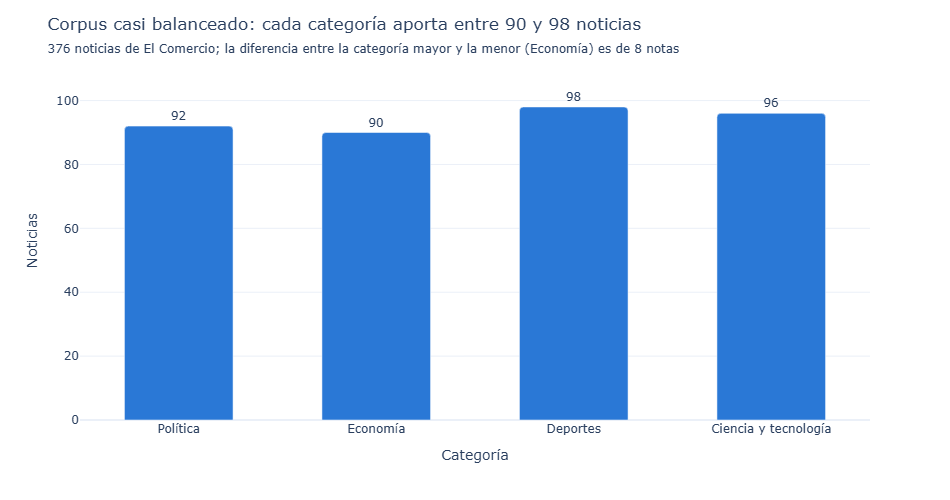

In [13]:
# Un color fijo por categoría (paleta categórica validada para series adyacentes)
COLORES = {"politica": "#2a78d6", "economia": "#eb6834", "deportes": "#1baf7a",
           "ciencia_tecnologia": "#eda100"}
ETIQ_LEGIBLE = {"politica": "Política", "economia": "Economía", "deportes": "Deportes",
                "ciencia_tecnologia": "Ciencia y tecnología"}
df["len_titular"] = df["titular"].str.len()

conteo = (df["etiqueta"].value_counts().reindex(ETIQUETAS)
            .rename_axis("etiqueta").reset_index(name="noticias"))
conteo["categoria"] = conteo["etiqueta"].map(ETIQ_LEGIBLE)
mn, mx = conteo["noticias"].min(), conteo["noticias"].max()
menor = ETIQ_LEGIBLE[conteo.loc[conteo["noticias"].idxmin(), "etiqueta"]]
if mx - mn <= 0.15 * mx:
    titulo = f"Corpus casi balanceado: cada categoría aporta entre {mn} y {mx} noticias"
else:
    titulo = f"Corpus desbalanceado: {menor} aporta solo {mn} noticias frente a {mx}"

# Una sola serie: un solo color; la categoría ya está en el eje x
fig1 = px.bar(conteo, x="categoria", y="noticias", text="noticias",
              labels={"categoria": "Categoría", "noticias": "Noticias"})
fig1.update_traces(marker_color=COLORES["politica"], textposition="outside", width=0.55)
fig1.update_layout(barcornerradius=4, yaxis_range=[0, mx * 1.15], title=dict(
    text=titulo,
    subtitle=dict(text=(f"{len(df)} noticias de {MEDIO}; la diferencia entre la categoría mayor "
                        f"y la menor ({menor}) es de {mx - mn} notas"))))
fig1.show()

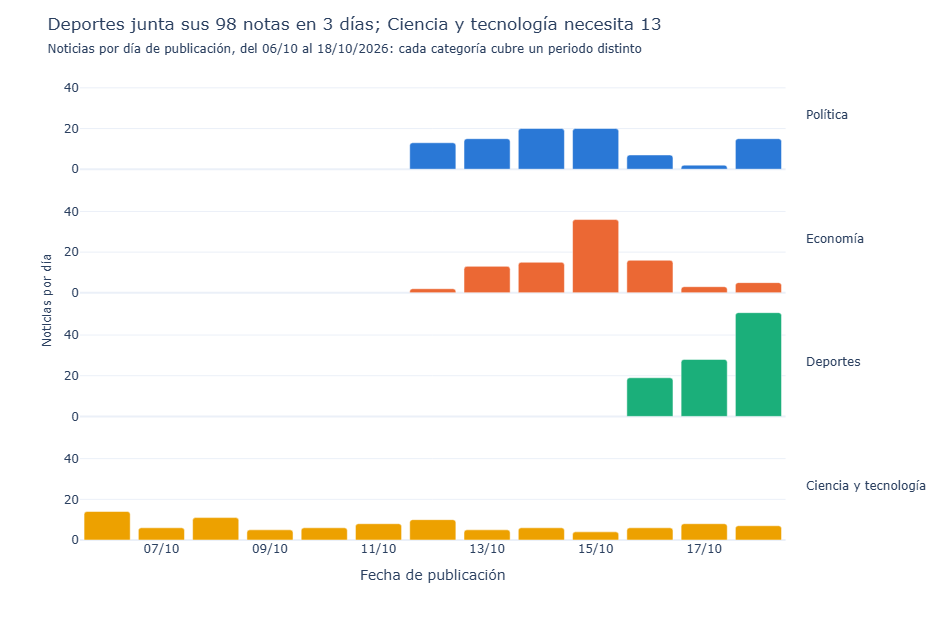

,desde,hasta,noticias,dias
etiqueta,,,,
politica,2026-10-12 12:22,2026-10-18 19:45,92,7
economia,2026-10-12 16:33,2026-10-18 15:38,90,7
deportes,2026-10-16 09:44,2026-10-18 19:38,98,3
ciencia_tecnologia,2026-10-06 08:05,2026-10-18 20:00,96,13


In [14]:
por_dia = (df.groupby([df["fecha_dt"].dt.date.rename("fecha"), "etiqueta"])
             .size().reset_index(name="noticias"))
rango = df.groupby("etiqueta")["fecha_dt"].agg(desde="min", hasta="max", noticias="size")
rango["dias"] = (rango["hasta"].dt.normalize() - rango["desde"].dt.normalize()).dt.days + 1
rapida, lenta = rango["dias"].idxmin(), rango["dias"].idxmax()

# Un panel por categoría con el mismo eje de fechas, para comparar el periodo que cubre cada una
fig2 = px.bar(por_dia, x="fecha", y="noticias", color="etiqueta", facet_row="etiqueta",
              color_discrete_map=COLORES, category_orders={"etiqueta": ETIQUETAS},
              labels={"fecha": "Fecha de publicación", "noticias": "Noticias", "etiqueta": "Categoría"})
fig2.for_each_annotation(lambda a: a.update(text=ETIQ_LEGIBLE[a.text.split("=")[-1]], textangle=0,
                                            xanchor="left", x=1.005))
fig2.update_layout(height=620, showlegend=False, bargap=0.15, barcornerradius=3,
                   margin=dict(r=150), title=dict(
    text=(f"{ETIQ_LEGIBLE[rapida]} junta sus {rango.loc[rapida, 'noticias']} notas en "
          f"{rango.loc[rapida, 'dias']} días; {ETIQ_LEGIBLE[lenta]} necesita {rango.loc[lenta, 'dias']}"),
    subtitle=dict(text=(f"Noticias por día de publicación, del {df['fecha_dt'].min():%d/%m} al "
                        f"{df['fecha_dt'].max():%d/%m/%Y}: cada categoría cubre un periodo distinto"))))
fig2.for_each_yaxis(lambda ax: ax.update(title_text=""))
fig2.update_xaxes(tickformat="%d/%m", dtick=2 * 86_400_000)
fig2.add_annotation(text="Noticias por día", xref="paper", yref="paper", x=-0.06, y=0.5,
                    textangle=-90, showarrow=False)
fig2.show()
rango.assign(desde=rango["desde"].dt.strftime("%Y-%m-%d %H:%M"),
             hasta=rango["hasta"].dt.strftime("%Y-%m-%d %H:%M")).reindex(ETIQUETAS)

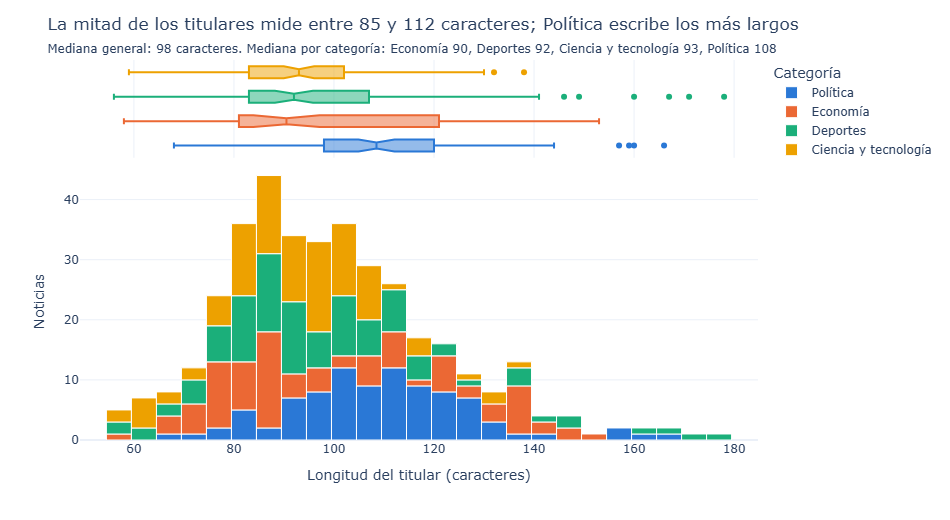

In [15]:
q1, mediana, q3 = df["len_titular"].quantile([0.25, 0.5, 0.75])
med_cat = df.groupby("etiqueta")["len_titular"].median().sort_values()

fig3 = px.histogram(df, x="len_titular", nbins=30, color="etiqueta", marginal="box",
                    color_discrete_map=COLORES, category_orders={"etiqueta": ETIQUETAS},
                    labels={"len_titular": "Longitud del titular (caracteres)", "etiqueta": "Categoría"})
fig3.for_each_trace(lambda t: t.update(name=ETIQ_LEGIBLE[t.name]))
fig3.update_traces(marker_line=dict(color="white", width=1), selector=dict(type="histogram"))
fig3.update_layout(height=520, yaxis_title="Noticias", legend_title_text="Categoría", title=dict(
    text=(f"La mitad de los titulares mide entre {q1:.0f} y {q3:.0f} caracteres; "
          f"{ETIQ_LEGIBLE[med_cat.index[-1]]} escribe los más largos"),
    subtitle=dict(text=(f"Mediana general: {mediana:.0f} caracteres. Mediana por categoría: "
                        + ", ".join(f"{ETIQ_LEGIBLE[k]} {v:.0f}" for k, v in med_cat.items())))))
fig3.show()

**Lectura de los gráficos**

1. **Balance:** las 4 categorías tienen entre 90 y 98 noticias (máximo 8 de diferencia). Para la Parte 2 no hace falta rebalancear, y el F1 macro y el accuracy deberían dar valores parecidos.
2. **Periodo cubierto:** el sitemap trae las 100 notas más recientes de cada sección, pero las secciones publican a ritmos muy distintos. Deportes cubre solo 3 días (16–18/10) y ciencia y tecnología, 13 (06–18/10). Esto significa que los titulares de una categoría pueden compartir los temas de esos días (por ejemplo, la Ley MAPE en política o un partido concreto en deportes), y el modelo podría aprenderse esos temas en lugar de la categoría. Es una limitación que se tendrá en cuenta al evaluar.
3. **Longitud:** la mitad de los titulares mide entre 85 y 112 caracteres. Política escribe los titulares más largos (mediana 108, frente a 90–93 en las demás), probablemente por las citas y los nombres de instituciones. El histograma no tiene valores sospechosos cerca de 0, y los extremos se revisan a continuación.

## 5. Validación: titulares más largos y más cortos
Se revisan los extremos del histograma para comprobar que son titulares reales y no errores de extracción (por ejemplo, texto del menú o un titular cortado).

In [16]:
cols = ["len_titular", "etiqueta", "seccion_original", "titular"]
with pd.option_context("display.max_colwidth", None):  # titular completo, sin recortar
    print("5 titulares MÁS LARGOS")
    display(df.nlargest(5, "len_titular")[cols].reset_index(drop=True))
    print("5 titulares MÁS CORTOS")
    display(df.nsmallest(5, "len_titular")[cols].reset_index(drop=True))

print(f"Rango de longitudes: {df['len_titular'].min()}–{df['len_titular'].max()} caracteres "
      f"(mediana {df['len_titular'].median():.0f}), el mismo eje que recorre el histograma.")
print("Titulares que coinciden con el nombre del diario o con textos genéricos:",
      int(df["titular"].str.lower().isin(["el comercio", "últimas noticias", "noticias"]).sum()))

5 titulares MÁS LARGOS


,len_titular,etiqueta,seccion_original,titular
0,178,deportes,deporte-total/futbol-peruano,"“El jugador peruano tiene un déficit grande en nutrición y táctica que resuelve a los 20 años, eso en Argentina es a los 12″: Urciuoli, el técnico revelación con Alianza Atlético"
1,171,deportes,deporte-total/futbol-peruano,El furioso “Que se dedique a administrar” de Guede a Franco Velazco y un Quevedo que reconquistó a Comando Sur: Lo que no se vio del 3-1 que mantiene a Alianza en la pelea
2,167,deportes,deporte-total,“Creo que puedo llegar a un top 3 sin que nadie se quede botado”: Raúl ‘Mono’ Orlandini le responde a El Comercio sobre las dos últimas etapas de Caminos del Inca 2026
3,166,politica,politica/gobierno,"Keiko Fujimori sobre Álvaro Vargas Llosa: “Confío en que su trayectoria, experiencia y compromiso contribuirán a fortalecer relaciones bilaterales y lazos de amistad”"
4,160,deportes,deporte-total,"“El día de mañana me encantaría ver a tantas niñas entrando al automovilismo”: Annia Cillóniz, líder en la categoría S1600, sobre sus sueños en Caminos del Inca"


5 titulares MÁS CORTOS


,len_titular,etiqueta,seccion_original,titular
0,56,deportes,deporte-total/futbol-peruano,CD Moquegua venció a FC Cajamarca por el Torneo Clausura
1,58,economia,economia/mercados,Precio del dólar en Perú: cierre del domingo 18 de octubre
2,58,deportes,deporte-total/futbol-mundial,"Neymar se rinde ante Lamine Yamal: ""Es el mejor del mundo"""
3,59,ciencia_tecnologia,tecnologia/actualidad,"Qué es la ""depresión sonriente"" y cómo puedes identificarla"
4,59,ciencia_tecnologia,tecnologia/actualidad,¿Qué secreto de longevidad atesora una tortuga de 194 años?


Rango de longitudes: 56–178 caracteres (mediana 98), el mismo eje que recorre el histograma.
Titulares que coinciden con el nombre del diario o con textos genéricos: 0


**Coherencia con el histograma:** los extremos (56 y 178 caracteres) son los bordes del histograma y corresponden a titulares reales y completos. Ninguno es texto del menú, ni un titular cortado, ni el nombre del diario.

- **Los más largos** son casi todos citas textuales de entrevistas (entre comillas y seguidas del nombre del entrevistado), sobre todo en deportes. Por eso la cola derecha del histograma es verde aunque política tenga la mediana más alta.
- **Los más cortos** son titulares informativos completos (quién + qué), como resultados de partidos o el precio del dólar.